# Apprentissage d'un modèle MR-Sort à $p$ catégories avec Gurobi (Jalon 1)

Les catégories $C^1 \prec \dots \prec C^p$ sont séparées par $p-1$ frontières $b^1,\dots,b^{p-1}$ (notées $b^h$, $h=1..p-1$). Un objet $x$ appartient à $C^h$ si et seulement si
$$\sum_{i:\,x_i\ge b^{h-1}_i} w_i \ge \lambda \quad\text{et}\quad \sum_{i:\,x_i\ge b^{h}_i} w_i < \lambda .$$

**Variables** : $b^h_i$, $w_i$, $\lambda$, $\alpha$ (marge, de signe quelconque), $\delta^h_i(x)\in\{0,1\}$, $w^h_i(x)$.

**Objectif** : $\max\ \alpha$

**Contraintes**
- $\sum_i w_i = 1$ ; ordre des frontières : $b^{h-1}_i \le b^h_i$.
- Définition de $\delta^h_i(x)$ (question v) : $x_i \ge b^h_i - M(1-\delta^h_i(x))$ et $x_i \le b^h_i - \varepsilon + M\delta^h_i(x)$.
- Définition de $w^h_i(x)=\delta^h_i(x)w_i$ (question vi) : $w_i\ge w^h_i(x)\ge 0$ et $\delta^h_i(x)\ge w^h_i(x)\ge \delta^h_i(x)+w_i-1$.
- Pour $x$ de classe $c$ : si $c\ge 2$, $\sum_i w^{c-1}_i(x)\ge \lambda+\alpha$ ; si $c\le p-1$, $\sum_i w^{c}_i(x)\le \lambda-\alpha-\varepsilon$.

Seules les frontières utiles pour la classe de $x$ (au plus 2) sont modélisées, ce qui réduit le nombre de variables binaires. Dans le code, les classes sont numérotées $0..p-1$ et les frontières $0..p-2$. Pour $p=2$, on retrouve le modèle de la question vii.

In [1]:
import numpy as np
import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt
import time

## 1. Modèle d'apprentissage

In [2]:
def classify(X, b, w, lam):
    """
    Classe les objets avec un modèle MR-Sort à p catégories.
    b : tableau (p-1, n) des frontières ; classes numérotées 0 .. p-1.
    Un objet est dans la classe c s'il bat (coalition >= lam) exactement c frontières.
    Tolérances 1e-6 alignées sur celles de Gurobi.
    """
    X = np.asarray(X, dtype=float)
    b = np.atleast_2d(b)
    gagne = np.stack([(X >= bh - 1e-6) @ w >= lam - 1e-6 for bh in b])  # (p-1, m)
    return gagne.sum(axis=0).astype(int)


_ENV = None


def gurobi_env():
    """Environnement Gurobi silencieux, créé une seule fois (n'affiche pas les informations de licence)."""
    global _ENV
    if _ENV is None:
        _ENV = gp.Env(empty=True)
        _ENV.setParam("OutputFlag", 0)
        _ENV.start()
    return _ENV


def learn_mr_sort(X, y, p=None, eps=1e-3, eps_w=1e-3, vmax=20.0, time_limit=60, verbose=False, compact=False):
    """
    Apprend un modèle MR-Sort à p catégories (questions vii et viii), objectif : max alpha.
    X : (m, n) performances ; y : (m,) classes dans {0, ..., p-1} (0 = la pire).
    eps   : écart pour l'inégalité stricte x_i < b_i (échelle des notes ; 1 si notes entières).
    eps_w : écart pour l'inégalité stricte sur la somme des poids (échelle [0,1]).
    compact=True : version allégée (moins de contraintes), de même optimum. Pour une frontière
    que l'objet doit atteindre, seules les contraintes "delta=1 => x>=b" et "w_i(x) <= delta*w_i"
    sont utiles ; pour une frontière qu'il ne doit pas atteindre, seules "delta=0 => x<b" et
    "w_i(x) >= delta + w_i - 1".
    Retourne (b, w, lam, alpha, nb_erreurs) avec b de forme (p-1, n).
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    m, n = X.shape
    if p is None:
        p = int(y.max()) + 1
    M = vmax + eps

    mdl = gp.Model("MRSort", env=gurobi_env())
    mdl.Params.OutputFlag = 1 if verbose else 0
    mdl.Params.TimeLimit = time_limit

    # Frontière h (h = 0..p-2) sépare la classe h de la classe h+1
    b     = mdl.addVars(p - 1, n, lb=0.0, ub=vmax, name="b")
    w     = mdl.addVars(n, lb=0.0, ub=1.0, name="w")
    lam   = mdl.addVar(lb=0.0, ub=1.0, name="lambda")
    alpha = mdl.addVar(lb=-1.0, ub=1.0, name="alpha")

    mdl.addConstr(w.sum() == 1)
    # Frontières ordonnées : b^h <= b^(h+1) sur chaque critère
    for h in range(p - 2):
        for i in range(n):
            mdl.addConstr(b[h, i] <= b[h + 1, i])

    def coalition(x, h, atteint):
        """Somme des poids des critères où l'objet x atteint la frontière h.
        atteint=True : l'objet doit atteindre la frontière ; False : il ne doit pas l'atteindre."""
        termes = []
        for i in range(n):
            d  = mdl.addVar(vtype=GRB.BINARY)          # delta_i(x) pour la frontière h
            wx = mdl.addVar(lb=0.0, ub=1.0)            # w_i(x) = delta * w_i
            # Question v : définition de delta
            if not compact or atteint:
                mdl.addConstr(b[h, i] - M * (1 - d) <= float(X[x, i]))     # delta=1 => x >= b
            if not compact or not atteint:
                mdl.addConstr(b[h, i] - eps + M * d >= float(X[x, i]))     # delta=0 => x < b
            # Question vi : wx = delta * w_i
            if not compact or atteint:
                mdl.addConstr(wx <= w[i])
                mdl.addConstr(wx <= d)
            if not compact or not atteint:
                mdl.addConstr(wx >= d + w[i] - 1)
            termes.append(wx)
        return gp.quicksum(termes)

    for x in range(m):
        c = y[x]
        if c >= 1:        # doit atteindre la frontière inférieure b^c (indice c-1)
            mdl.addConstr(coalition(x, c - 1, True) >= lam + alpha)
        if c <= p - 2:    # ne doit pas atteindre la frontière supérieure (indice c)
            mdl.addConstr(coalition(x, c, False) <= lam - alpha - eps_w)

    mdl.setObjective(alpha, GRB.MAXIMIZE)
    mdl.optimize()
    if mdl.SolCount == 0:   # ex. limite de temps atteinte avant toute solution
        raise RuntimeError(f"Gurobi n'a trouvé aucune solution (statut {mdl.Status}) : augmenter time_limit.")

    b_v = np.array([[b[h, i].X for i in range(n)] for h in range(p - 1)])
    w_v = np.array([w[i].X for i in range(n)])
    n_err = int(np.sum(classify(X, b_v, w_v, lam.X) != y))
    return b_v, w_v, lam.X, alpha.X, n_err


## 2. Vérification sur l'exemple de la question i ($p=2$)

In [3]:
noms = ["Alice", "Bob", "Charlie", "David"]
X = np.array([[11, 12, 13, 12], [13, 12, 15, 10], [11, 13, 11, 13], [12, 12, 16, 12]])
y = classify(X, np.full((1, 4), 12.0), np.array([0.25, 0.15, 0.2, 0.4]), 0.66)
print(dict(zip(noms, y.tolist())))

b, w, lam, alpha, err = learn_mr_sort(X, y, p=2)
print("b =", b.round(2).tolist(), "| w =", w.round(3), "| lambda =", round(lam, 3),
      "| alpha =", round(alpha, 3), "| erreurs =", err)
print("Classes prédites :", classify(X, b, w, lam))

{'Alice': 1, 'Bob': 0, 'Charlie': 0, 'David': 1}
b = [[13.0, 13.0, 11.0, 10.0]] | w = [0.  0.  0.5 0.5] | lambda = 0.75 | alpha = 0.249 | erreurs = 0
Classes prédites : [1 0 0 1]


## 3. Exemple avec $p=3$ catégories

On fixe un modèle ground truth à 3 classes, on classe 30 objets, puis on réapprend le modèle.

In [4]:
rng = np.random.default_rng(1)
b0 = np.array([[8, 8, 8, 8], [14, 14, 14, 14]], dtype=float)
w0, lam0 = np.array([0.4, 0.3, 0.2, 0.1]), 0.6
X3 = rng.uniform(0, 20, (30, 4))
y3 = classify(X3, b0, w0, lam0)
print("Effectifs par classe :", np.bincount(y3, minlength=3))

b, w, lam, alpha, err = learn_mr_sort(X3, y3, p=3)
print("b =\n", b.round(2), "\nw =", w.round(3), "| lambda =", round(lam, 3),
      "| alpha =", round(alpha, 3), "| erreurs =", err)

Effectifs par classe : [12 13  5]
b =
 [[ 7.52  6.84 15.07 15.06]
 [15.01 14.5  15.07 19.61]] 
w = [0.25 0.25 0.25 0.25] | lambda = 0.376 | alpha = 0.124 | erreurs = 0


## 4. Protocole de test du jalon 1

1. Ground truth $M'$ aléatoire (poids, $\lambda$, $p-1$ frontières).
2. Learning set généré et classé avec $M'$.
3. Apprentissage de $M^*$.
4. Jeu de test classé avec $M'$ et $M^*$ : qualité = proportion d'objets affectés à la même classe.

In [5]:
def random_model(n, p, rng, vmax=20.0):
    """Modèle MR-Sort aléatoire : poids, lambda, p-1 frontières ordonnées."""
    w = rng.dirichlet(np.ones(n))
    lam = rng.uniform(0.5, 0.8)
    b = np.sort(rng.uniform(0.15 * vmax, 0.85 * vmax, (p - 1, n)), axis=0)
    return b, w, lam


def experiment(n=4, p=2, m_learn=40, m_test=1000, seed=0, **kw):
    """Protocole du jalon 1 : ground truth -> learning set -> apprentissage -> test."""
    rng = np.random.default_rng(seed)
    b0, w0, lam0 = random_model(n, p, rng)
    X_l = rng.uniform(0, 20, (m_learn, n))
    y_l = classify(X_l, b0, w0, lam0)
    b, w, lam, alpha, err = learn_mr_sort(X_l, y_l, p=p, **kw)
    X_t = rng.uniform(0, 20, (m_test, n))
    quality = np.mean(classify(X_t, b0, w0, lam0) == classify(X_t, b, w, lam))
    return quality, err


In [6]:
q, err = experiment(p=3, seed=0)
print(f"Qualité sur le test : {q:.3f} | erreurs sur le learning set : {err}")

Qualité sur le test : 0.951 | erreurs sur le learning set : 0


## 5. Répétition sur 20 essais, pour plusieurs valeurs de $p$

p = 2 : qualité moyenne 0.949 (écart-type 0.046, min 0.844, max 0.999) - 1.9 s
p = 3 : qualité moyenne 0.920 (écart-type 0.050, min 0.808, max 0.995) - 2.3 s
p = 4 : qualité moyenne 0.878 (écart-type 0.071, min 0.748, max 0.976) - 2.7 s


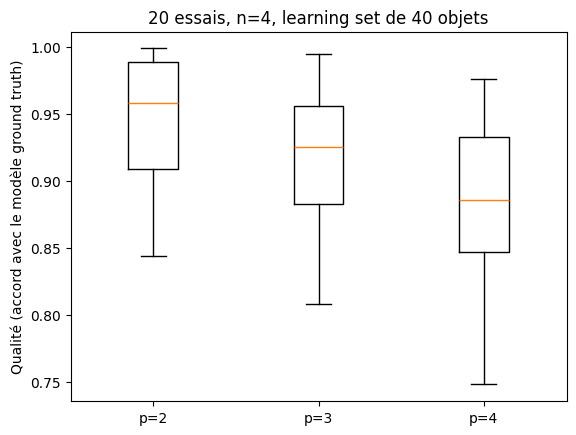

In [6]:
N_REP = 20
resultats = {}
for p in [2, 3, 4]:
    t0 = time.time()
    qs = np.array([experiment(n=4, p=p, m_learn=40, seed=k, time_limit=30)[0] for k in range(N_REP)])
    resultats[p] = qs
    print(f"p = {p} : qualité moyenne {qs.mean():.3f} (écart-type {qs.std():.3f}, "
          f"min {qs.min():.3f}, max {qs.max():.3f}) - {time.time() - t0:.1f} s")

plt.boxplot([resultats[p] for p in resultats], tick_labels=[f"p={p}" for p in resultats])
plt.ylabel("Qualité (accord avec le modèle ground truth)")
plt.title(f"{N_REP} essais, n=4, learning set de 40 objets")
plt.show()

## 6. Apprentissage sur Dataset0

60 objets, 5 critères (notes entières de 0 à 100), 3 catégories numérotées de 1 à 3 dans le fichier (décalées à 0..2). `eps = 1` pour les notes entières, `vmax = 100`.

In [7]:
lignes = [l.split() for l in open("dataset0.txt") if l.strip()]
data = np.array([[float(v) for v in l[1:]] for l in lignes[1:]])   # saute l'en-tête et le nom de l'objet
Xd = data[:, :-1]
yd = data[:, -1].astype(int) - 1
print("objets :", Xd.shape[0], "| critères :", Xd.shape[1], "| effectifs par classe :", np.bincount(yd))

b, w, lam, alpha, err = learn_mr_sort(Xd, yd, p=3, eps=1.0, eps_w=1e-3, vmax=100.0,
                                      time_limit=250, compact=True)
print("Frontières b :\n", b.round(2))
print("Poids w :", w.round(4), "| lambda =", round(lam, 4), "| alpha =", round(alpha, 4))
print("Erreurs sur le learning set :", err, "/", len(yd))

objets : 60 | critères : 5 | effectifs par classe : [19 25 16]
Frontières b :
 [[38. 35. 30. 35. 31.]
 [64. 53. 37. 54. 50.]]
Poids w : [0.1429 0.2857 0.1429 0.1429 0.2857] | lambda = 0.6434 | alpha = 0.0709
Erreurs sur le learning set : 0 / 60
